<a href="https://colab.research.google.com/github/M-H26/Traffic-Sign-Recognition/blob/main/notebooks/00_Data_and_Baselines.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [26]:
%cd /content
!git clone https://github.com/M-H26/Traffic-Sign-Recognition.git

/content
Cloning into 'Traffic-Sign-Recognition'...
remote: Enumerating objects: 52, done.
remote: Counting objects: 100% (52/52), done.
remote: Compressing objects: 100% (41/41), done.
remote: Total 52 (delta 13), reused 5 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (52/52), 10.84 KiB | 2.17 MiB/s, done.
Resolving deltas: 100% (13/13), done.


## 1. Dataset Structure Inspection

In this section, we inspect the dataset archive to understand its folder structure, identify image directories and annotation files, and determine how the images and labels are organized before preprocessing.

In [4]:
import os
# Dataset ZIP path
ZIP_PATH = "/content/drive/MyDrive/Project Basics of AI 2026/Data Set/Raw Data/data.zip"

# Check file existence
if os.path.exists(ZIP_PATH):
    file_size = os.path.getsize(ZIP_PATH) / (1024 ** 2)
    print("Dataset ZIP found successfully.")
    print(f"File size: {file_size:.2f} MB")
else:
    print("Dataset ZIP not found. Please check the path.")

Dataset ZIP found successfully.
File size: 305.68 MB


In [5]:
import zipfile

with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
    files = zip_ref.namelist()

print(f"Total files: {len(files)}")
print("\nFirst 20 entries:")
for file in files[:20]:
    print(file)

Total files: 51935

First 20 entries:
Meta/
Meta.csv
Meta/.~lock.ClassesInformation.ods#
Meta/.~lock.ClassesInformationStrong.ods#
Meta/0.png
Meta/1.png
Meta/10.png
Meta/11.png
Meta/12.png
Meta/13.png
Meta/14.png
Meta/15.png
Meta/16.png
Meta/17.png
Meta/18.png
Meta/19.png
Meta/2.png
Meta/20.png
Meta/21.png
Meta/22.png


In [6]:
from collections import Counter
import os

with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
    files = zip_ref.namelist()

# Identify top-level directories and files
top_level = Counter()

for file in files:
    if file.startswith('__MACOSX/') or '/.~lock.' in file:
        continue

    parts = file.strip('/').split('/')
    if len(parts) > 1:
        top_level[parts[0]] += 1
    elif file:
        top_level[f"[FILE] {parts[0]}"] += 1

print("Dataset Main Structure:\n")

for name, count in sorted(top_level.items()):
    print(f"{name}: {count} entries")

Dataset Main Structure:

Meta: 43 entries
Test: 12631 entries
Train: 39252 entries
[FILE] Meta: 1 entries
[FILE] Meta.csv: 1 entries
[FILE] Test: 1 entries
[FILE] Test.csv: 1 entries
[FILE] Train: 1 entries
[FILE] Train.csv: 1 entries
[FILE] signnames.csv: 1 entries


## 2. Annotation Files Inspection

In this section, we inspect the dataset annotation files to understand their structure, identify the available columns, and determine how image paths are associated with their labels.

In [7]:
import pandas as pd

with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
    csv_files = ['Train.csv', 'Test.csv', 'Meta.csv']

    for file in csv_files:
        df = pd.read_csv(zip_ref.open(file))

        print(f"\n{'='*50}")
        print(f"File: {file}")
        print(f"Shape: {df.shape}")
        print(f"Columns: {df.columns.tolist()}")
        display(df.head())


File: Train.csv
Shape: (39209, 8)
Columns: ['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId', 'Path']


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,27,26,5,5,22,20,20,/code/Train/20/00020_00000_00000.png
1,28,27,5,6,23,22,20,/code/Train/20/00020_00000_00001.png
2,29,26,6,5,24,21,20,/code/Train/20/00020_00000_00002.png
3,28,27,5,6,23,22,20,/code/Train/20/00020_00000_00003.png
4,28,26,5,5,23,21,20,/code/Train/20/00020_00000_00004.png



File: Test.csv
Shape: (12630, 8)
Columns: ['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId', 'Path']


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,53,54,6,5,48,49,16,/code/Test/00000.png
1,42,45,5,5,36,40,1,/code/Test/00001.png
2,48,52,6,6,43,47,38,/code/Test/00002.png
3,27,29,5,5,22,24,33,/code/Test/00003.png
4,60,57,5,5,55,52,11,/code/Test/00004.png



File: Meta.csv
Shape: (43, 5)
Columns: ['Path', 'ClassId', 'ShapeId', 'ColorId', 'SignId']


,Path,ClassId,ShapeId,ColorId,SignId
0,/code/Meta/27.png,27,0,0,1.32
1,/code/Meta/0.png,0,1,0,3.29
2,/code/Meta/1.png,1,1,0,3.29
3,/code/Meta/10.png,10,1,0,3.27
4,/code/Meta/11.png,11,0,0,1.22


## 3. Data Integrity Checks

We validate the dataset by checking:
- Missing values in annotation files.
- Whether all image paths exist in the ZIP archive.
- Duplicate image paths and records.
- Whether the dataset contains all 43 expected classes.

In [8]:
# Load annotation files
with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
    train_df = pd.read_csv(zip_ref.open('Train.csv'))
    test_df = pd.read_csv(zip_ref.open('Test.csv'))
    meta_df = pd.read_csv(zip_ref.open('Meta.csv'))

    # Get actual file paths inside the ZIP archive
    zip_files = set(zip_ref.namelist())

# Normalize CSV paths to match ZIP paths
train_paths = train_df['Path'].str.replace('/code/', '', n=1)
test_paths = test_df['Path'].str.replace('/code/', '', n=1)

# Check missing image files
missing_train = [p for p in train_paths if p not in zip_files]
missing_test = [p for p in test_paths if p not in zip_files]

# Check class IDs
expected_classes = set(range(43))
train_classes = set(train_df['ClassId'].unique())
test_classes = set(test_df['ClassId'].unique())

# Display validation results
print("Missing Values:")
print(f"Train: {train_df.isnull().sum().sum()}")
print(f"Test: {test_df.isnull().sum().sum()}")
print(f"Meta: {meta_df.isnull().sum().sum()}")

print("\nMissing Image Files:")
print(f"Train: {len(missing_train)}")
print(f"Test: {len(missing_test)}")

print("\nDuplicate Paths:")
print(f"Train: {train_df['Path'].duplicated().sum()}")
print(f"Test: {test_df['Path'].duplicated().sum()}")

print("\nClass Validation:")
print(f"Train classes: {len(train_classes)}")
print(f"Test classes: {len(test_classes)}")
print(f"Missing train classes: {sorted(expected_classes - train_classes)}")
print(f"Missing test classes: {sorted(expected_classes - test_classes)}")

Missing Values:
Train: 0
Test: 0
Meta: 1

Missing Image Files:
Train: 0
Test: 0

Duplicate Paths:
Train: 0
Test: 0

Class Validation:
Train classes: 43
Test classes: 43
Missing train classes: []
Missing test classes: []


## 4. Missing Values and Duplicate Records

In this section, we identify the exact location of missing values in the metadata file and check for duplicate image paths and annotation records.

In [9]:
# Locate missing values in Meta.csv
print("Missing Values in Meta.csv:")
display(meta_df[meta_df.isnull().any(axis=1)])

# Check duplicate image paths
print("\nDuplicate Image Paths:")
print(f"Train: {train_df['Path'].duplicated().sum()}")
print(f"Test: {test_df['Path'].duplicated().sum()}")

# Check duplicate records
print("\nDuplicate Records:")
print(f"Train: {train_df.duplicated().sum()}")
print(f"Test: {test_df.duplicated().sum()}")
print(f"Meta: {meta_df.duplicated().sum()}")

Missing Values in Meta.csv:


,Path,ClassId,ShapeId,ColorId,SignId
24,/code/Meta/30.png,30,0,0,NaN



Duplicate Image Paths:
Train: 0
Test: 0

Duplicate Records:
Train: 0
Test: 0
Meta: 0


## 5. Traffic Sign Class Mapping

In this section, we inspect the class names file to establish a consistent mapping between the 43 class IDs and their corresponding traffic sign labels.

In [10]:
# Load class names
with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
    signnames_df = pd.read_csv(zip_ref.open('signnames.csv'))

# Inspect the mapping file
print("Shape:", signnames_df.shape)
print("Columns:", signnames_df.columns.tolist())

display(signnames_df.head(10))

print("\nTotal Classes:", len(signnames_df))
print("Unique Class IDs:", signnames_df['ClassId'].nunique())

Shape: (43, 2)
Columns: ['ClassId', 'SignName']


,ClassId,SignName
0,0,Speed limit (20km/h)
1,1,Speed limit (30km/h)
2,2,Speed limit (50km/h)
3,3,Speed limit (60km/h)
4,4,Speed limit (70km/h)
5,5,Speed limit (80km/h)
6,6,End of speed limit (80km/h)
7,7,Speed limit (100km/h)
8,8,Speed limit (120km/h)
9,9,No passing



Total Classes: 43
Unique Class IDs: 43


## 6. Class Mapping Validation

In this section, we validate the consistency of class IDs across the training, testing, and metadata files against the official class names mapping.

In [11]:
# Create the shared class mapping
class_mapping = dict(
    zip(signnames_df['ClassId'], signnames_df['SignName'])
)

# Compare class IDs across files
mapping_classes = set(class_mapping.keys())
train_classes = set(train_df['ClassId'].unique())
test_classes = set(test_df['ClassId'].unique())
meta_classes = set(meta_df['ClassId'].unique())

print("Class Mapping Validation:")
print(f"Mapping classes: {len(mapping_classes)}")
print(f"Train classes: {len(train_classes)}")
print(f"Test classes: {len(test_classes)}")
print(f"Meta classes: {len(meta_classes)}")

print("\nMissing from Mapping:")
print("Train:", sorted(train_classes - mapping_classes))
print("Test:", sorted(test_classes - mapping_classes))
print("Meta:", sorted(meta_classes - mapping_classes))

print("\nMapping Status:",
      "Valid" if (
          train_classes == mapping_classes
          and test_classes == mapping_classes
          and meta_classes == mapping_classes
      ) else "Check Required")

Class Mapping Validation:
Mapping classes: 43
Train classes: 43
Test classes: 43
Meta classes: 43

Missing from Mapping:
Train: []
Test: []
Meta: []

Mapping Status: Valid


## 7. Image Validation

In this section, we verify that dataset images can be successfully loaded and that their actual dimensions match the dimensions recorded in the annotation files.

In [12]:
from PIL import Image
from tqdm.auto import tqdm

validation_results = {
    "unreadable": [],
    "dimension_mismatch": []
}

with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:

    for df in [train_df, test_df]:

        for _, row in tqdm(df.iterrows(), total=len(df)):

            image_path = row['Path'].replace('/code/', '', 1)

            try:
                with zip_ref.open(image_path) as image_file:
                    with Image.open(image_file) as img:
                        img.verify()

                    # Reopen image to inspect dimensions
                    with zip_ref.open(image_path) as image_file:
                        with Image.open(image_file) as img:
                            actual_width, actual_height = img.size

                if (actual_width != row['Width'] or
                    actual_height != row['Height']):
                    validation_results["dimension_mismatch"].append(image_path)

            except Exception:
                validation_results["unreadable"].append(image_path)

print("\nImage Validation Results")
print("Unreadable images:", len(validation_results["unreadable"]))
print("Dimension mismatches:", len(validation_results["dimension_mismatch"]))

  0%|          | 0/39209 [00:00<?, ?it/s]

  0%|          | 0/12630 [00:00<?, ?it/s]


Image Validation Results
Unreadable images: 0
Dimension mismatches: 0


## 8. Building the Dataset Index

In this section, we create a unified dataset index containing image paths, class IDs, class names, and dataset split information. This index will be reused throughout the project.

In [13]:
# Prepare training and testing indexes
train_index = train_df[['Path', 'ClassId']].copy()
train_index['Split'] = 'Train'

test_index = test_df[['Path', 'ClassId']].copy()
test_index['Split'] = 'Test'

# Combine both datasets
dataset_index = pd.concat(
    [train_index, test_index],
    ignore_index=True
)

# Add class names
dataset_index['SignName'] = dataset_index['ClassId'].map(class_mapping)

# Reset paths to archive-relative paths
dataset_index['Path'] = dataset_index['Path'].str.replace(
    '/code/', '', n=1
)

# Display results
print("Dataset Index Shape:", dataset_index.shape)
print("\nSplit Distribution:")
print(dataset_index['Split'].value_counts())

print("\nMissing Class Names:", dataset_index['SignName'].isnull().sum())

display(dataset_index.head())

Dataset Index Shape: (51839, 4)

Split Distribution:
Split
Train    39209
Test     12630
Name: count, dtype: int64

Missing Class Names: 0


,Path,ClassId,Split,SignName
0,Train/20/00020_00000_00000.png,20,Train,Dangerous curve to the right
1,Train/20/00020_00000_00001.png,20,Train,Dangerous curve to the right
2,Train/20/00020_00000_00002.png,20,Train,Dangerous curve to the right
3,Train/20/00020_00000_00003.png,20,Train,Dangerous curve to the right
4,Train/20/00020_00000_00004.png,20,Train,Dangerous curve to the right


## 9. Saving the Dataset Index

We save the validated dataset index as a CSV file on Google Drive so that all team members can reuse the same image paths and class mapping.

In [14]:
OUTPUT_DIR = "/content/drive/MyDrive/Project Basics of AI 2026/Processed Data"

os.makedirs(OUTPUT_DIR, exist_ok=True)

INDEX_PATH = os.path.join(OUTPUT_DIR, "dataset_index.csv")

dataset_index.to_csv(INDEX_PATH, index=False)

print("Dataset index saved successfully.")
print("Path:", INDEX_PATH)

Dataset index saved successfully.
Path: /content/drive/MyDrive/Project Basics of AI 2026/Processed Data/dataset_index.csv


## 10. OpenCV Preprocessing – CLAHE

In this section, we apply Contrast Limited Adaptive Histogram Equalization (CLAHE) using OpenCV.

The technique is applied to the Luminance channel in the LAB color space to improve image contrast while preserving color information.

We compare the original and processed images to evaluate the visual impact of CLAHE.

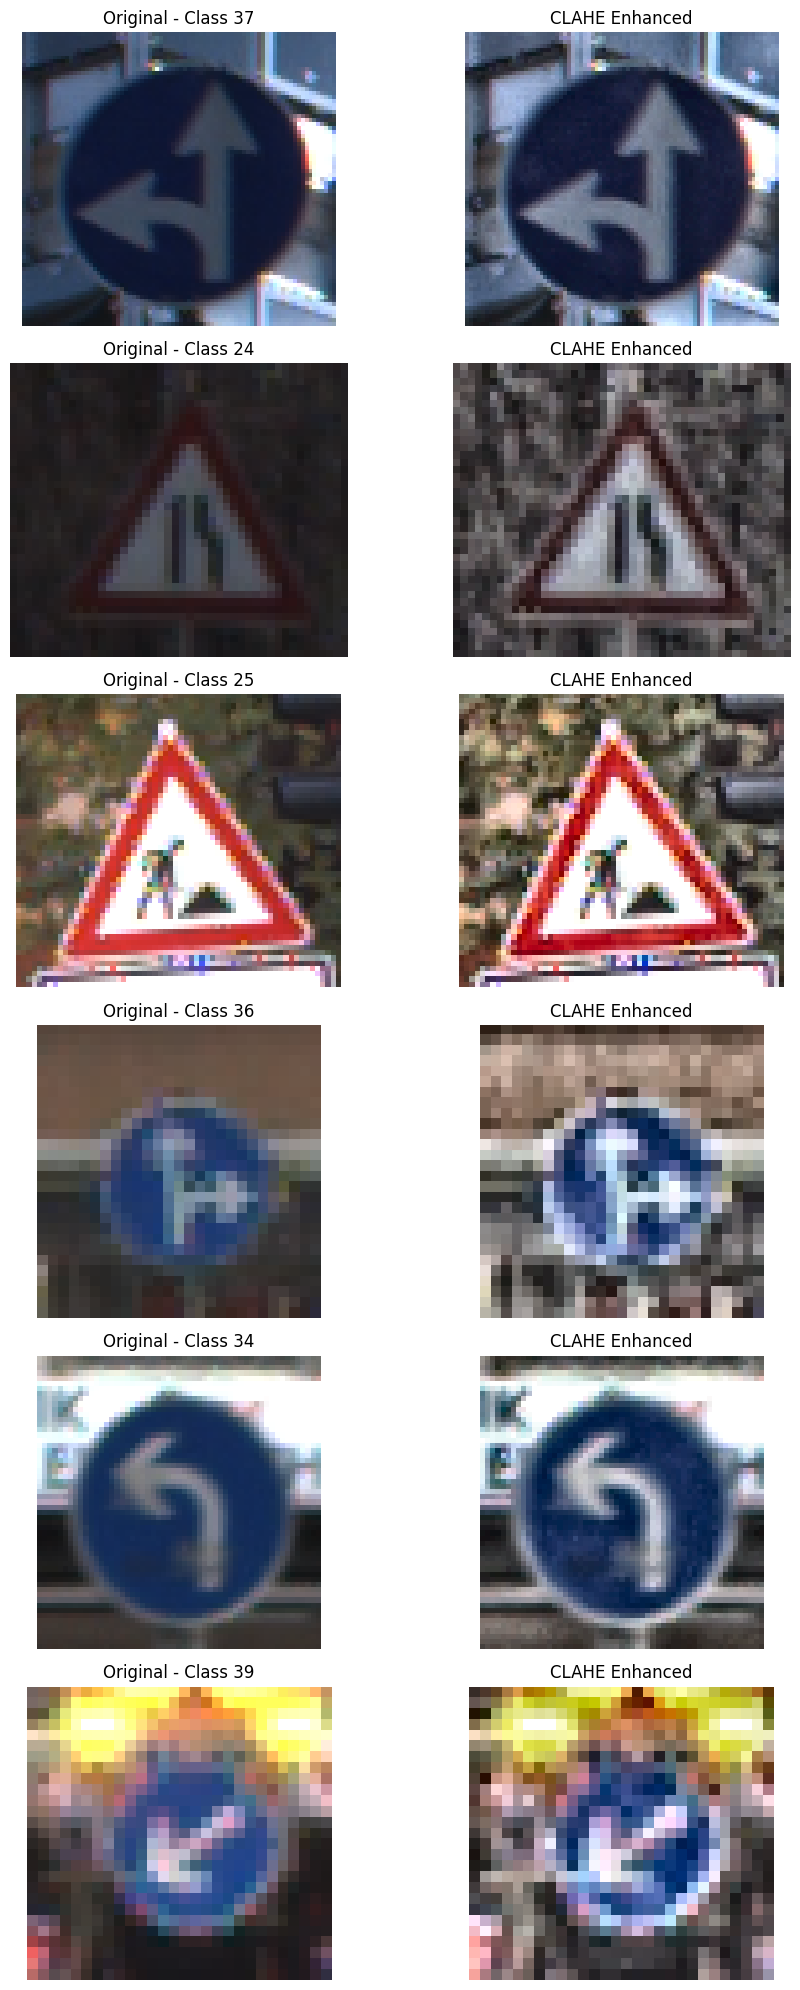

In [15]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import zipfile
import random

# Configure CLAHE
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

def apply_clahe(image):
    # Convert RGB to LAB
    lab_image = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)

    # Split LAB channels
    l_channel, a_channel, b_channel = cv2.split(lab_image)

    # Apply CLAHE to the L channel only
    enhanced_l = clahe.apply(l_channel)

    # Merge channels and convert back to RGB
    enhanced_lab = cv2.merge((enhanced_l, a_channel, b_channel))
    enhanced_image = cv2.cvtColor(enhanced_lab, cv2.COLOR_LAB2RGB)

    return enhanced_image


# Select 6 images from different classes
sample_df = (
    train_df.groupby('ClassId', group_keys=False)
    .sample(n=1, random_state=42)
    .sample(n=6, random_state=42)
)

fig, axes = plt.subplots(6, 2, figsize=(10, 20))

with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:

    for i, (_, row) in enumerate(sample_df.iterrows()):

        image_path = row['Path'].replace('/code/', '', 1)

        with zip_ref.open(image_path) as image_file:
            image = np.array(Image.open(image_file).convert('RGB'))

        enhanced_image = apply_clahe(image)

        axes[i, 0].imshow(image)
        axes[i, 0].set_title(f"Original - Class {row['ClassId']}")
        axes[i, 0].axis('off')

        axes[i, 1].imshow(enhanced_image)
        axes[i, 1].set_title("CLAHE Enhanced")
        axes[i, 1].axis('off')

plt.tight_layout()
plt.show()

## 11. CLAHE Evaluation and Decision

CLAHE was applied to the luminance channel using the LAB color space.

The visual comparison showed that CLAHE improved local contrast in some images, but also amplified noise and pixelation in others.

Current Configuration:
- Clip Limit: 2.0
- Tile Grid Size: (8, 8)
- Color Space: LAB
- Applied Channel: Luminance (L)

Decision:
The original images will be preserved, and CLAHE will remain an optional preprocessing technique.

Its final adoption will be determined through a controlled validation experiment comparing model performance on original and CLAHE-processed images using the same model configuration and data split.

## 12. Train / Validation Split

The official test set is preserved and will only be used for final evaluation.

We split the original training data into training and validation sets using stratified sampling to preserve class proportions.

Configuration:
- Validation Size: 20%
- Random Seed: 42
- Stratification: ClassId

In [17]:
from sklearn.model_selection import train_test_split
import os

RANDOM_SEED = 42
VALIDATION_SIZE = 0.20

# Separate the official training and testing data
original_train = dataset_index[
    dataset_index['Split'] == 'Train'
].copy()

official_test = dataset_index[
    dataset_index['Split'] == 'Test'
].copy()

# Create stratified training and validation sets
train_split, val_split = train_test_split(
    original_train,
    test_size=VALIDATION_SIZE,
    random_state=RANDOM_SEED,
    stratify=original_train['ClassId']
)

# Assign split names
train_split = train_split.copy()
val_split = val_split.copy()
official_test = official_test.copy()

train_split['Split'] = 'Train'
val_split['Split'] = 'Validation'
official_test['Split'] = 'Test'

# Combine all splits
final_dataset_index = pd.concat(
    [train_split, val_split, official_test],
    ignore_index=True
)

# Verify split sizes
print(final_dataset_index['Split'].value_counts())

print("\nTotal samples:", len(final_dataset_index))
print("Duplicate image paths:", final_dataset_index['Path'].duplicated().sum())

# Verify that all splits contain the same 43 classes
print("\nClasses per split:")
print(final_dataset_index.groupby('Split')['ClassId'].nunique())

# Save the shared split
SPLIT_PATH = os.path.join(OUTPUT_DIR, "final_dataset_index.csv")

final_dataset_index.to_csv(SPLIT_PATH, index=False)

print("\nSaved shared dataset split to:", SPLIT_PATH)

Split
Train         31367
Test          12630
Validation     7842
Name: count, dtype: int64

Total samples: 51839
Duplicate image paths: 0

Classes per split:
Split
Test          43
Train         43
Validation    43
Name: ClassId, dtype: int64

Saved shared dataset split to: /content/drive/MyDrive/Project Basics of AI 2026/Processed Data/final_dataset_index.csv


## 13. Extracting Dataset Images

We extract the dataset images from the original ZIP archive into the Colab runtime.

The original ZIP file remains unchanged on Google Drive. The extracted files are used by the PyTorch Dataset.

In [18]:
EXTRACT_DIR = "/content/gtsrb_dataset"

if not os.path.exists(os.path.join(EXTRACT_DIR, "Train")):
    print("Extracting dataset...")

    with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
        zip_ref.extractall(EXTRACT_DIR)

    print("Extraction completed.")

else:
    print("Dataset already extracted.")

print("Train folder exists:",
      os.path.exists(os.path.join(EXTRACT_DIR, "Train")))

print("Test folder exists:",
      os.path.exists(os.path.join(EXTRACT_DIR, "Test")))

Extracting dataset...
Extraction completed.
Train folder exists: True
Test folder exists: True


## 14. Image Preprocessing and Augmentation

All images are converted to RGB and resized to 224 × 224 pixels.

ImageNet mean and standard deviation are used for normalization.

Training augmentation includes small random rotations, translations, and scaling. No random augmentation is applied to validation or test images.

CLAHE remains optional and is disabled by default.

In [19]:
import torch
from torchvision import transforms
from PIL import Image
import cv2
import numpy as np

IMAGE_SIZE = 224
BATCH_SIZE = 32
NUM_CLASSES = 43

# ImageNet normalization
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Keep CLAHE optional
USE_CLAHE = False

# CLAHE configuration
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

def apply_clahe(image):
    image_array = np.array(image.convert("RGB"))

    lab_image = cv2.cvtColor(
        image_array,
        cv2.COLOR_RGB2LAB
    )

    l_channel, a_channel, b_channel = cv2.split(lab_image)
    enhanced_l = clahe.apply(l_channel)

    enhanced_lab = cv2.merge(
        (enhanced_l, a_channel, b_channel)
    )

    enhanced_rgb = cv2.cvtColor(
        enhanced_lab,
        cv2.COLOR_LAB2RGB
    )

    return Image.fromarray(enhanced_rgb)


# Training transformations
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomAffine(
        degrees=8,
        translate=(0.05, 0.05),
        scale=(0.90, 1.10)
    ),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.10
    ),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

# Deterministic validation and testing transformations
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

print("Preprocessing configuration ready.")
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("CLAHE enabled:", USE_CLAHE)

Preprocessing configuration ready.
Image size: 224
Batch size: 32
CLAHE enabled: False


## 15. PyTorch Dataset and DataLoaders

We implement a reusable PyTorch Dataset that:
- Loads images using the shared dataset index.
- Converts images to RGB.
- Optionally applies CLAHE.
- Applies the appropriate transformation for each split.
- Returns the image tensor and its class label.

Separate DataLoaders are created for training, validation, and testing.

In [20]:
from torch.utils.data import Dataset, DataLoader

class TrafficSignDataset(Dataset):

    def __init__(self, dataframe, root_dir, transform=None,
                 use_clahe=False):

        self.dataframe = dataframe.reset_index(drop=True)
        self.root_dir = root_dir
        self.transform = transform
        self.use_clahe = use_clahe

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        image_path = os.path.join(
            self.root_dir,
            row['Path']
        )

        try:
            image = Image.open(image_path).convert("RGB")
        except Exception as error:
            raise RuntimeError(
                f"Could not load image: {image_path}"
            ) from error

        if self.use_clahe:
            image = apply_clahe(image)

        if self.transform:
            image = self.transform(image)

        label = int(row['ClassId'])

        return image, label


# Separate dataframes
train_data = final_dataset_index[
    final_dataset_index['Split'] == 'Train'
].copy()

val_data = final_dataset_index[
    final_dataset_index['Split'] == 'Validation'
].copy()

test_data = final_dataset_index[
    final_dataset_index['Split'] == 'Test'
].copy()


# Create datasets
train_dataset = TrafficSignDataset(
    train_data,
    EXTRACT_DIR,
    transform=train_transform,
    use_clahe=USE_CLAHE
)

val_dataset = TrafficSignDataset(
    val_data,
    EXTRACT_DIR,
    transform=eval_transform,
    use_clahe=USE_CLAHE
)

test_dataset = TrafficSignDataset(
    test_data,
    EXTRACT_DIR,
    transform=eval_transform,
    use_clahe=USE_CLAHE
)


# Reproducible DataLoader shuffling
generator = torch.Generator()
generator.manual_seed(RANDOM_SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
    generator=generator
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("Datasets and DataLoaders created successfully.")
print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Datasets and DataLoaders created successfully.
Train: 31367
Validation: 7842
Test: 12630


## 16. DataLoader Verification

We verify the DataLoaders by checking:
- Image tensor shape.
- Label shape and valid class range.
- Pixel values after normalization.
- Sample images and their corresponding class names.

The test set is checked for loading only; it is not used for training or model selection.

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Minimum label: 2
Maximum label: 40
Normalized pixel range: -2.1179039478302 2.640000104904175

Batch verification passed.


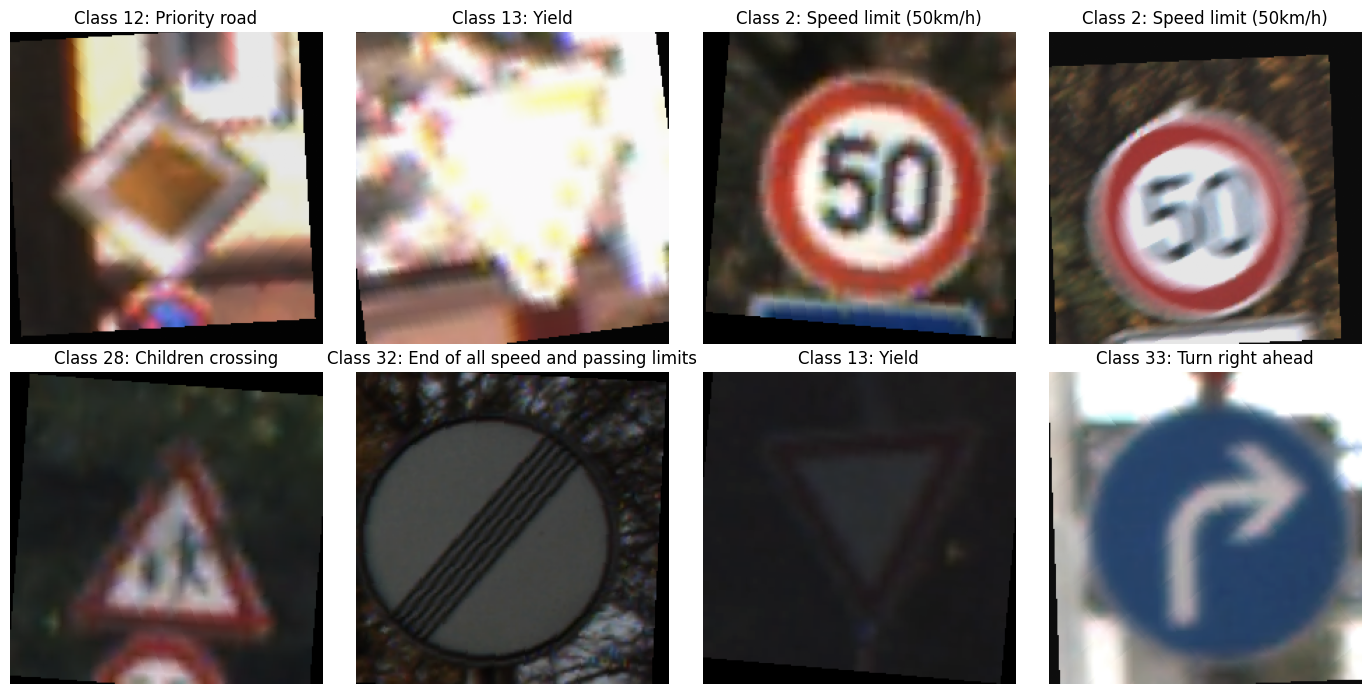

In [22]:
# Load one training batch
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

print("Minimum label:", labels.min().item())
print("Maximum label:", labels.max().item())

print("Normalized pixel range:",
      images.min().item(),
      images.max().item())

# Verify batch dimensions
assert images.shape[1:] == (3, IMAGE_SIZE, IMAGE_SIZE)
assert labels.min() >= 0
assert labels.max() < NUM_CLASSES

print("\nBatch verification passed.")


# Display sample images
mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std = torch.tensor(IMAGENET_STD).view(3, 1, 1)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for i, ax in enumerate(axes.flat):

    image = images[i] * std + mean
    image = image.permute(1, 2, 0).numpy()
    image = np.clip(image, 0, 1)

    label = labels[i].item()
    class_name = class_mapping.get(label, str(label))

    ax.imshow(image)
    ax.set_title(f"Class {label}: {class_name}")
    ax.axis("off")

plt.tight_layout()
plt.show()